In [3]:
import torchvision
import torch
import matplotlib.pyplot as plt
import numpy as np
import copy

from torch import nn
from torchvision.datasets import FashionMNIST
from torchvision.transforms import ToTensor
from torch.utils.data import DataLoader, TensorDataset, Subset
from sklearn.preprocessing import MinMaxScaler
from torchmetrics.classification import Accuracy, ConfusionMatrix

In [4]:
device = 'cuda' if torch.cuda.is_available() else 'cpu'
device

'cpu'

In [5]:
train_data = FashionMNIST('./data', train=True, download=True, transform=ToTensor())
test_data = FashionMNIST('./data', train=False, download=True, transform=ToTensor())

idx_1 = torch.where((train_data.targets != 0) & (train_data.targets != 3))[0]
idx_2 = torch.where((test_data.targets != 0) & (test_data.targets != 3))[0]

train_dataset = Subset(train_data, idx_1)
test_dataset = Subset(test_data, idx_2)

train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=64, shuffle=False)

100%|██████████| 26.4M/26.4M [00:02<00:00, 12.8MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 198kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.33MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 11.5MB/s]


In [6]:
class Model_1(nn.Module):
    def __init__(self):
        super().__init__()
        self.model = nn.Sequential(
            nn.GroupNorm(num_groups=1, num_channels=1),
            nn.Flatten(),
            nn.Linear(28*28, 128, bias=False),
            nn.LayerNorm(128),
            nn.ReLU(),
            nn.Linear(128, 64, bias=False),
            nn.LayerNorm(64),
            nn.ReLU(),
            nn.Linear(64, 10)
        )

    def forward(self, X):
        return self.model(X)

In [7]:
def train_model(model, epochs):
  optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
  train_loss= []
  test_loss = []
  loss_function = nn.CrossEntropyLoss()
  for epoch in range(epochs):
    epoch_loss = 0
    model.train()
    for X_train, y_train in train_loader:
      X_train = X_train.to(device)
      y_train = y_train.to(device)
      loss = loss_function(model(X_train), y_train)
      optimizer.zero_grad()
      loss.backward()
      nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
      optimizer.step()
      epoch_loss += loss.item()
    train_loss.append(epoch_loss/len(train_loader))

    model.eval()
    with torch.inference_mode():
      test_epoch_loss = 0
      for X_test, y_test in test_loader:
        X_test = X_test.to(device)
        y_test = y_test.to(device)
        loss = loss_function(model(X_test), y_test)
        test_epoch_loss += loss.item()
      test_loss.append(test_epoch_loss/len(test_loader))
  return train_loss, test_loss




In [8]:
def initialize(m):
  if isinstance(m, nn.Linear):
    nn.init.kaiming_normal_(m.weight, mode='fan_in', nonlinearity='relu')
    if m.bias is not None:
      nn.init.zeros_(m.bias)

model = Model_1().to(device).apply(initialize)
train_loss, test_loss = train_model(model, 15)


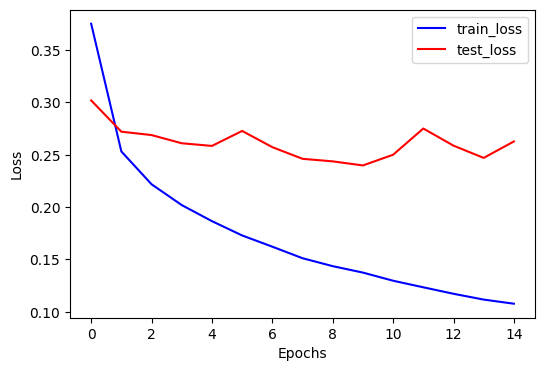

In [9]:

plt.figure(figsize=(6, 4))
plt.plot(train_loss, label='train_loss', color='blue')
plt.plot(test_loss, label='test_loss', color='red')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.show()

/usr/local/lib/python3.13/dist-packages/torchmetrics/utilities/prints.py:43: UserWarning: 20 NaN values found in confusion matrix have been replaced with zeros.
  warnings.warn(*args, **kwargs)


<Figure size 600x400 with 0 Axes>

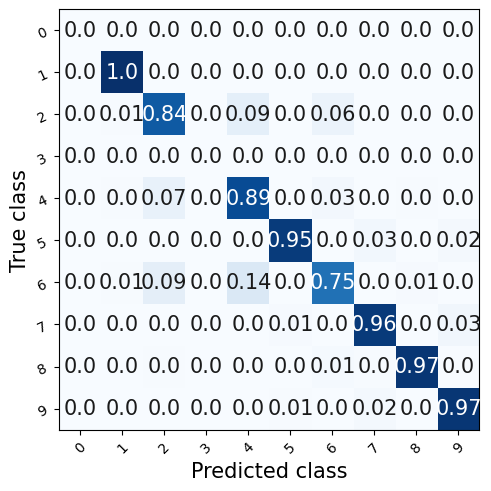

tensor(0.9154)

In [10]:
metric = ConfusionMatrix('multiclass', num_classes=10, normalize='true')
metric_2 = Accuracy(task='multiclass', num_classes=10)
model.eval()
with torch.inference_mode():
  for X_test, y_test in test_loader:
    X_test = X_test.to(device)
    y_test = y_test.to(device)
    y_pred = model(X_test)
    metric_2.update(y_pred, y_test)
    metric.update(y_pred, y_test)
plt.figure(figsize=(6, 4))
metric.plot(cmap='Blues')
plt.show()

metric_2.compute()

In [39]:
layers = copy.deepcopy(model.model[:-1])
for layer in layers:
  for param in layer.parameters():
    param.requires_grad = False

class Model_2(nn.Module):
  def __init__(self, layers):
    super().__init__()
    self.model = nn.Sequential(
        *layers,
        nn.Linear(64, 4)     #To match the indices because of 3
    )
  def forward(self, X):
    return self.model(X)

train_data = FashionMNIST('./data', train=True, download=True, transform=ToTensor())
test_data = FashionMNIST('./data', train=False, download=True, transform=ToTensor())


idx_1 = torch.where((train_data.targets == 0) | (train_data.targets == 3))[0]
idx_2 = torch.where((test_data.targets == 0) | (test_data.targets == 3))[0]

train_loader_2 = DataLoader(Subset(train_data, idx_1), batch_size=64, shuffle=True)
test_loader_2 = DataLoader(Subset(test_data, idx_2), batch_size=64, shuffle=False)

print(torch.unique(next(iter(test_loader_2))[1]))


model_2 = Model_2(layers).to(device)
model_2.model[-1].apply(initialize)

tensor([0, 3])


Linear(in_features=64, out_features=4, bias=True)

In [40]:
def train_model(model, epochs):
  optimizer = torch.optim.Adam(filter(
                                      lambda param: param.requires_grad,
                                      model.parameters()),
                                      lr=1e-3)
  train_loss= []
  test_loss = []
  loss_function = nn.CrossEntropyLoss()
  for epoch in range(epochs):
    epoch_loss = 0
    model.train()
    for X_train, y_train in train_loader_2:
      X_train = X_train.to(device)
      y_train = y_train.to(device)
      loss = loss_function(model(X_train), y_train)
      optimizer.zero_grad()
      loss.backward()
      nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
      optimizer.step()
      epoch_loss += loss.item()
    train_loss.append(epoch_loss/len(train_loader_2))

    model.eval()
    with torch.inference_mode():
      test_epoch_loss = 0
      for X_test, y_test in test_loader_2:
        X_test = X_test.to(device)
        y_test = y_test.to(device)
        loss = loss_function(model(X_test), y_test)
        test_epoch_loss += loss.item()
      test_loss.append(test_epoch_loss/len(test_loader_2))
  return train_loss, test_loss

train_loss, test_loss = train_model(model_2, 4)


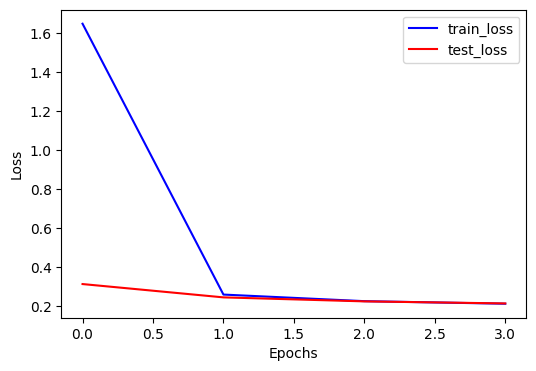

In [41]:

plt.figure(figsize=(6, 4))
plt.plot(train_loss, label='train_loss', color='blue')
plt.plot(test_loss, label='test_loss', color='red')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.show()

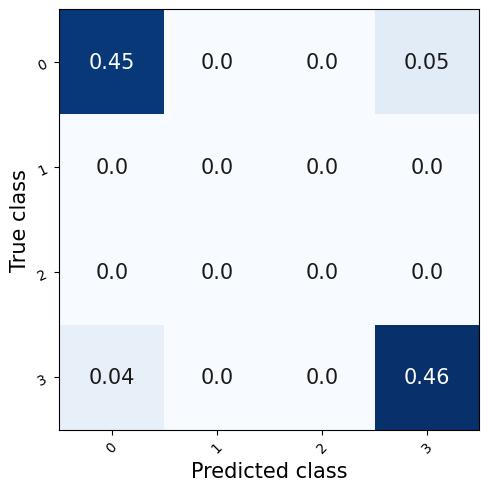

Test Accuracy: 0.9110


In [42]:
metric = ConfusionMatrix('multiclass', num_classes=4, normalize='all').to(device)
metric_2 = Accuracy(task='multiclass', num_classes=4).to(device)

model_2.eval()
with torch.inference_mode():
    for X_test, y_test in test_loader_2:
        X_test = X_test.to(device)
        y_test = y_test.to(device)
        y_pred = model_2(X_test)
        metric_2.update(y_pred, y_test)
        metric.update(y_pred, y_test)

# plt.figure(figsize=(6, 4))
metric.plot(cmap='Blues')
plt.show()

print(f"Test Accuracy: {metric_2.compute().item():.4f}")


The new head starts with random weights, so at first it produces large, meaningless errors. If the backbone were unfrozen, those errors would flow back and damage the good pretrained weights. Training the head first makes it sensible, and then fine-tuning only makes small adjustments.

In [43]:
model_2.requires_grad_(True)

Model_2(
  (model): Sequential(
    (0): GroupNorm(1, 1, eps=1e-05, affine=True, bias=True)
    (1): Flatten(start_dim=1, end_dim=-1)
    (2): Linear(in_features=784, out_features=128, bias=False)
    (3): LayerNorm((128,), eps=1e-05, elementwise_affine=True, bias=True)
    (4): ReLU()
    (5): Linear(in_features=128, out_features=64, bias=False)
    (6): LayerNorm((64,), eps=1e-05, elementwise_affine=True, bias=True)
    (7): ReLU()
    (8): Linear(in_features=64, out_features=4, bias=True)
  )
)

In [48]:
def train_model(model, epochs):
  optimizer = torch.optim.Adam(filter(
                                      lambda param: param.requires_grad,
                                      model.parameters()),
                                      lr=1e-5)
  train_loss= []
  test_loss = []
  loss_function = nn.CrossEntropyLoss()
  for epoch in range(epochs):
    epoch_loss = 0
    model.train()
    for X_train, y_train in train_loader_2:
      X_train = X_train.to(device)
      y_train = y_train.to(device)
      loss = loss_function(model(X_train), y_train)
      optimizer.zero_grad()
      loss.backward()
      nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
      optimizer.step()
      epoch_loss += loss.item()
    train_loss.append(epoch_loss/len(train_loader_2))

    model.eval()
    with torch.inference_mode():
      test_epoch_loss = 0
      for X_test, y_test in test_loader_2:
        X_test = X_test.to(device)
        y_test = y_test.to(device)
        loss = loss_function(model(X_test), y_test)
        test_epoch_loss += loss.item()
      test_loss.append(test_epoch_loss/len(test_loader_2))
  return train_loss, test_loss

train_loss, test_loss = train_model(model_2, 10)


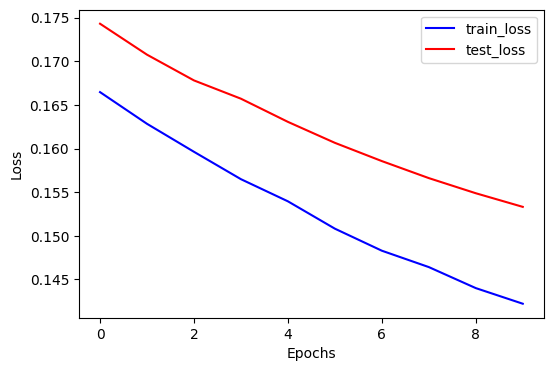

In [49]:

plt.figure(figsize=(6, 4))
plt.plot(train_loss, label='train_loss', color='blue')
plt.plot(test_loss, label='test_loss', color='red')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.show()

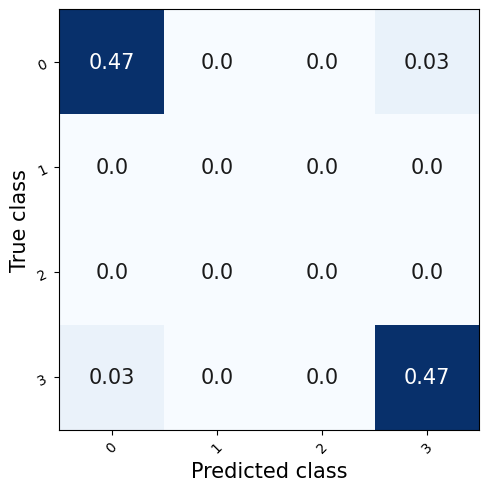

Test Accuracy: 0.9385


In [50]:
metric = ConfusionMatrix('multiclass', num_classes=4, normalize='all').to(device)
metric_2 = Accuracy(task='multiclass', num_classes=4).to(device)

model_2.eval()
with torch.inference_mode():
    for X_test, y_test in test_loader_2:
        X_test = X_test.to(device)
        y_test = y_test.to(device)
        y_pred = model_2(X_test)
        metric_2.update(y_pred, y_test)
        metric.update(y_pred, y_test)

# plt.figure(figsize=(6, 4))
metric.plot(cmap='Blues')
plt.show()

print(f"Test Accuracy: {metric_2.compute().item():.4f}")
